# SET50 Phase 2: Factor and signal research

Pre-registered cross-sectional study. Historical adjusted opens are research labels, not confirmed execution prices. Evaluation is chronological but was not wholly unseen after Phase 1.

In [1]:
from pathlib import Path
import pandas as pd, json
from IPython.display import display, Image
run=Path('C:\\Users\\Windows 10\\Downloads\\tradeSim0.2.5\\research_set50_factors\\results\\20261026T161657Z_64b58b98')
assert json.loads((run/'status.json').read_text())['status']=='complete'
print('Run:',run.name)

Run: 20261026T161657Z_64b58b98


## Objectives and data overview

Test predictive ranking, economic magnitude, stability, and feasibility separately. The permitted list is current and historical membership is unavailable.

,symbol,rows,first,last,missing_calendar_sessions,invalid_ohlc_rows
0,ADVANC,738,2023-09-21,2026-10-06,0,0
1,AOT,738,2023-09-21,2026-10-06,0,0
2,AWC,738,2023-09-21,2026-10-06,0,0
3,BANPU,45,2026-08-04,2026-10-06,693,0
4,BBL,738,2023-09-21,2026-10-06,0,0
5,BCP,738,2023-09-21,2026-10-06,0,0
6,BDMS,738,2023-09-21,2026-10-06,0,0
7,BEM,738,2023-09-21,2026-10-06,0,0
8,BH,738,2023-09-21,2026-10-06,0,0
9,BJC,738,2023-09-21,2026-10-06,0,0


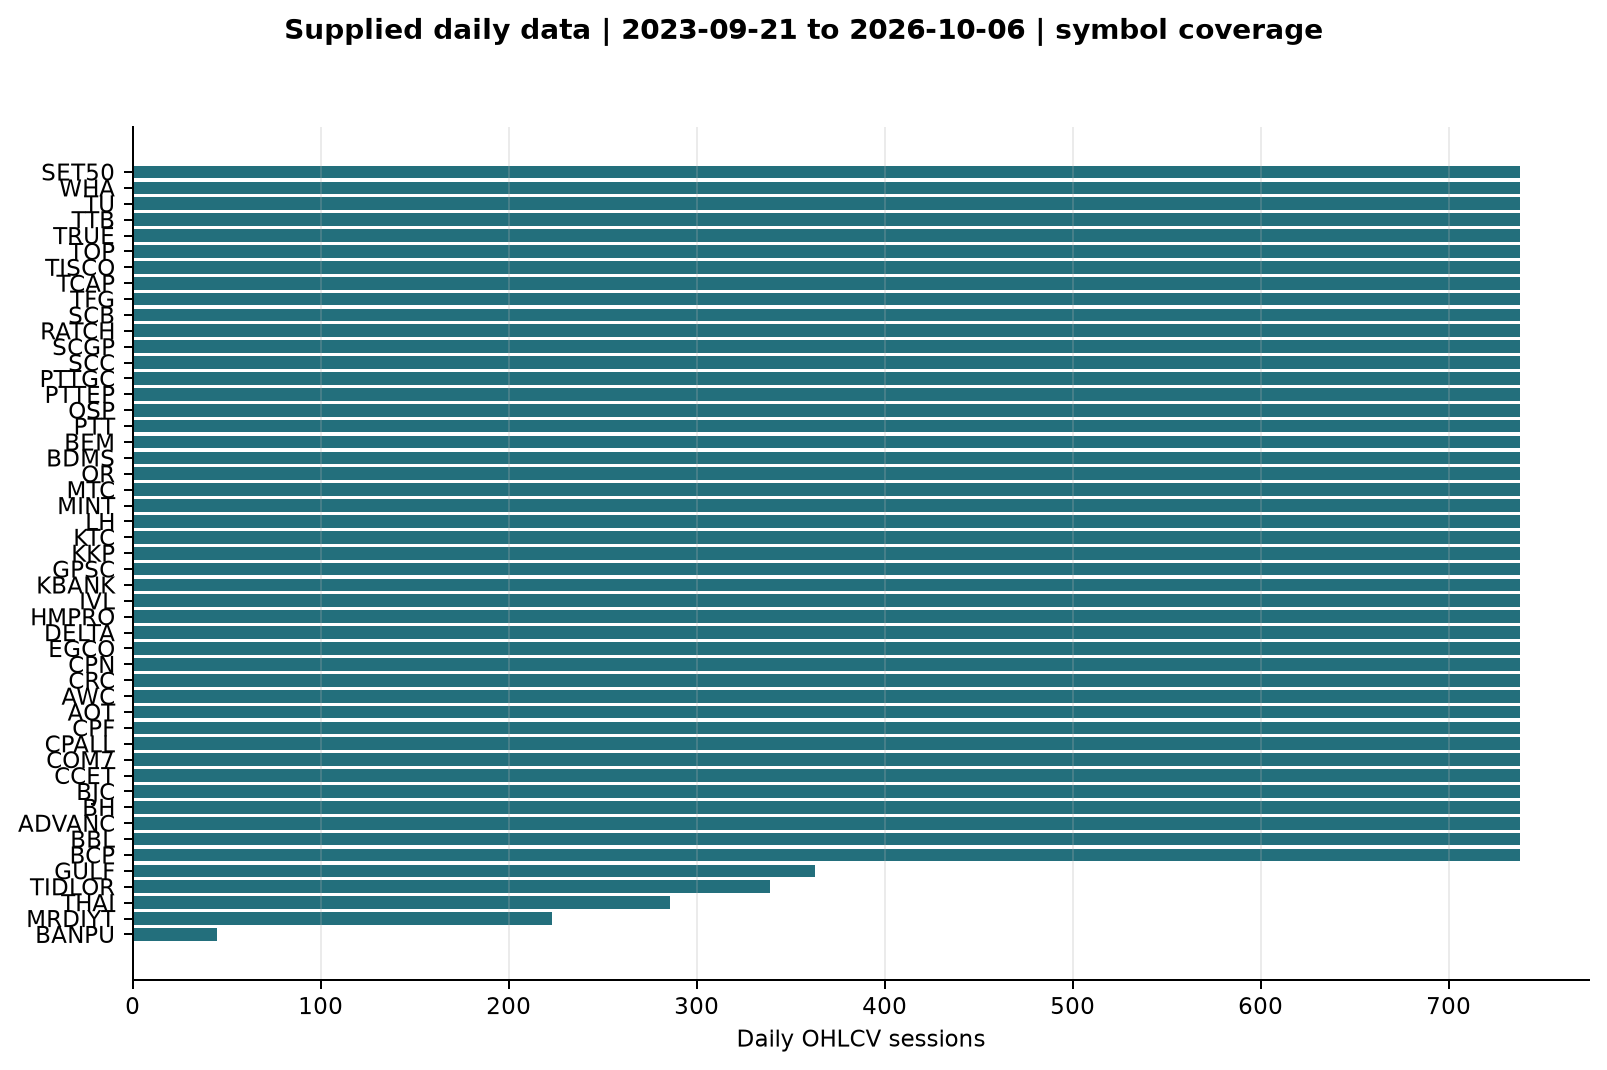

In [2]:
audit=pd.read_csv(run/'data_inventory.csv'); display(audit[['symbol','rows','first','last','missing_calendar_sessions','invalid_ohlc_rows']].head(12)); display(Image(filename=str(run/'figures/data_coverage.png')))

## Feature definitions and timing

All features use completed closes and volume through `t`. The earliest entry is `t+1` open; horizon `h` exits at `t+1+h` open. Relative strength subtracts the same benchmark return from every stock, so it does not create a new same-date ranking.

In [3]:
config=json.loads((run/'config.json').read_text()); print('Factors:',len(config['factor_directions']),'Horizons:',config['horizons']); display(pd.read_csv(run/'timeline.csv').head()); from research_set50_factors.data import load_daily; from research_set50_factors.factors import make_factors; symbols,calendar,daily,_=load_daily(); factors,_,_=make_factors(symbols,calendar,daily); date=calendar[100]; symbol='ADVANC'; print('Example 5-session momentum:',symbol,str(date.date()),round(float(factors['mom_5'].loc[date,symbol]),5))

Factors: 25 Horizons: [1, 3, 5, 10, 20]


,signal_date,latest_observation,earliest_entry
0,2023-09-21,2023-09-21,2023-09-22
1,2023-09-22,2023-09-22,2023-09-25
2,2023-09-25,2023-09-25,2023-09-26
3,2023-09-26,2023-09-26,2023-09-27
4,2023-09-27,2023-09-27,2023-09-28


Example 5-session momentum: ADVANC 2024-02-16 -0.00467


## Predictive power: IC and Rank IC

Correlations are computed separately each date, then summarized across dates. The information ratio is unannualized mean IC divided by daily IC standard deviation. Intervals use a time-series-aware HAC estimate.

,factor,dates,mean_ic,mean_rank_ic,rank_hac_lo,rank_hac_hi,rank_fdr_q
137,low_atr14,474,-0.012850,0.026386,-0.024791,0.077563,0.785537
157,mom_10,474,0.031570,0.025810,-0.010901,0.062520,0.785537
182,relative_10,474,0.031570,0.025810,-0.010901,0.062520,0.785537
202,reversal_1,474,0.016337,0.023651,0.008563,0.038740,0.026545
147,low_vol_20,474,-0.019127,0.023155,-0.027419,0.073728,0.785537
142,low_vol_10,474,-0.019349,0.022274,-0.026153,0.070701,0.785537
222,sma20_above_sma60,474,0.028579,0.022115,-0.015370,0.059600,0.785537
127,above_sma20,474,0.031572,0.019319,-0.021049,0.059687,0.785537
132,log_trading_value20,474,0.007514,0.017896,-0.014698,0.050491,0.785537
247,volume_surprise,474,0.023486,0.016089,-0.003114,0.035292,0.598537


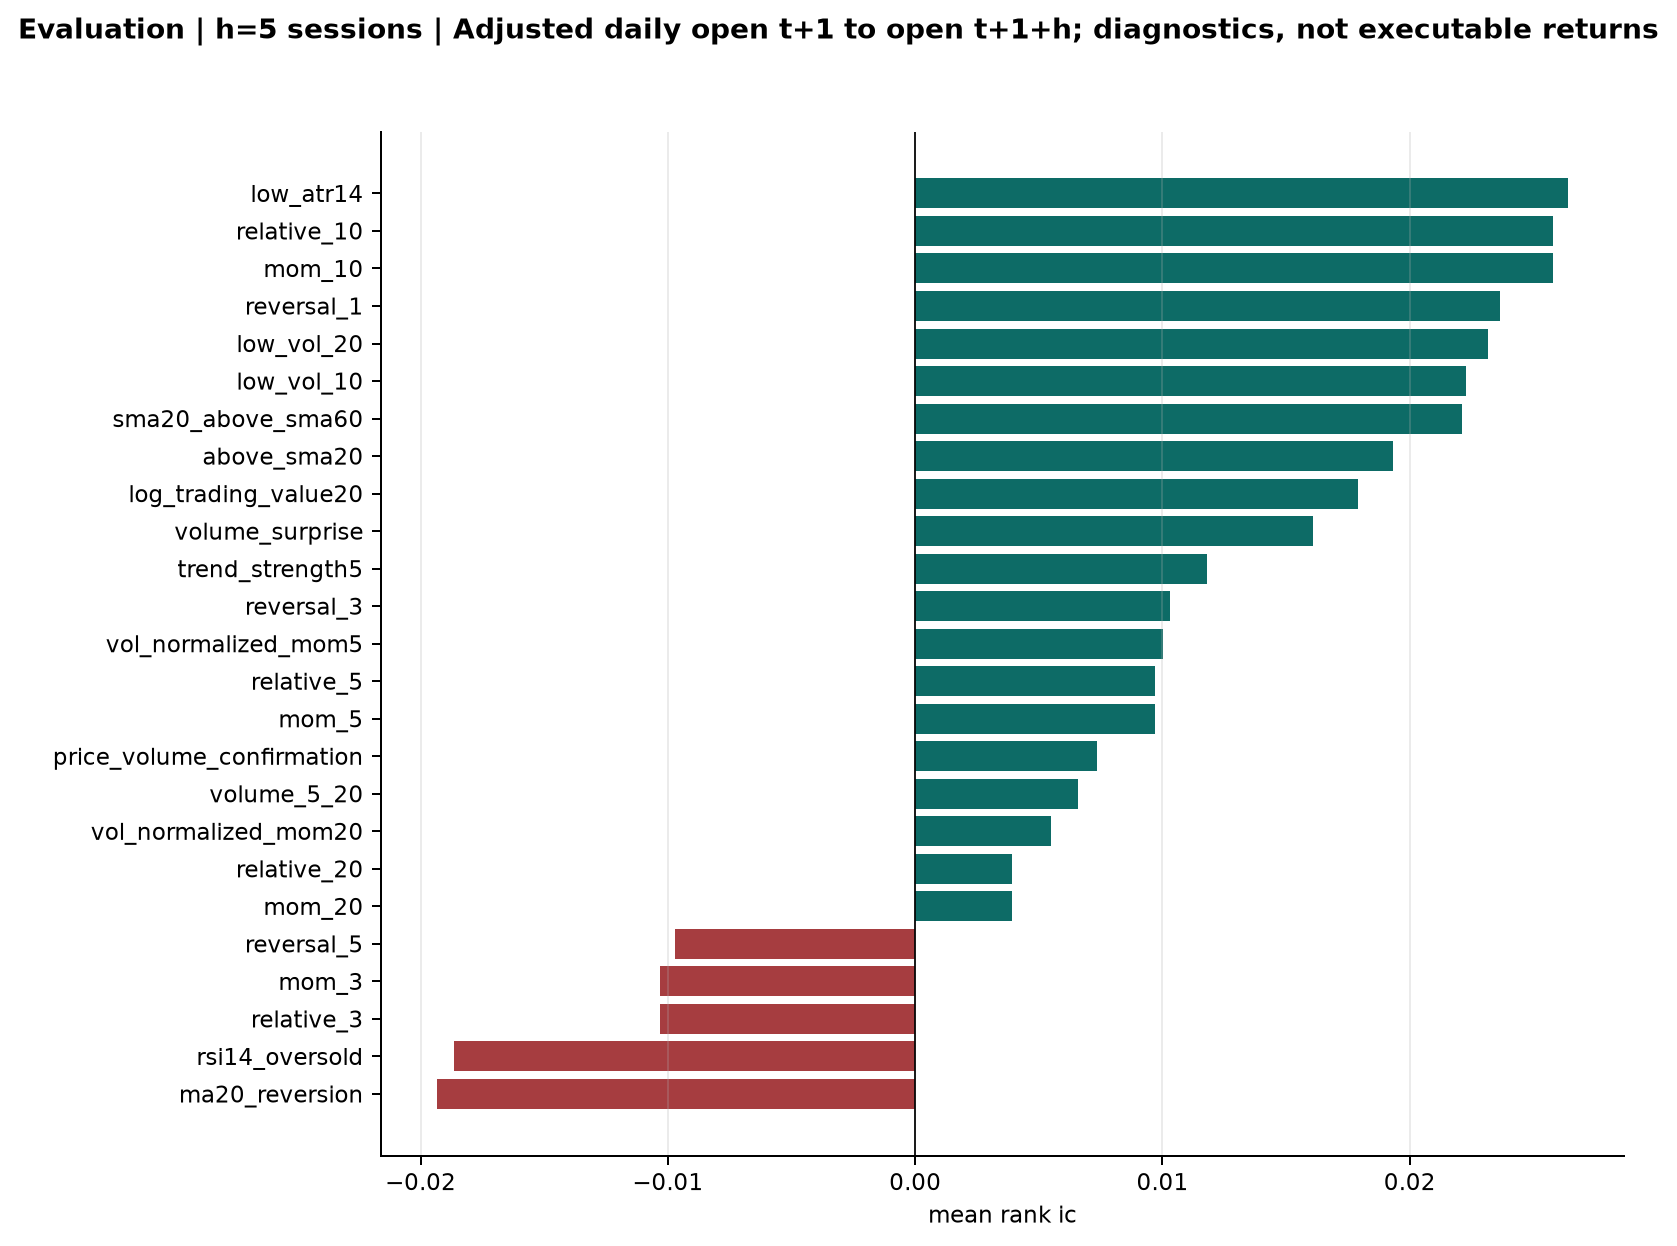

In [4]:
summary=pd.read_csv(run/'factor_summary.csv'); ev=summary[(summary.role=='evaluation')&(summary.horizon==5)].sort_values('mean_rank_ic',ascending=False); display(ev[['factor','dates','mean_ic','mean_rank_ic','rank_hac_lo','rank_hac_hi','rank_fdr_q']]); display(Image(filename=str(run/'figures/evaluation_rank_ic_comparison.png')))

## Quantile analysis

Top minus bottom is only a factor diagnostic. A long-only portfolio needs absolute and benchmark-relative top-group returns to be useful.

,factor,dates,mean_return,benchmark_relative
814,mom_20,474,0.004442,0.002442
939,relative_20,474,0.004442,0.002442
639,above_sma20,474,0.004424,0.002424
1114,sma20_above_sma60,474,0.004347,0.002346
1164,vol_normalized_mom20,474,0.004248,0.002247
1139,trend_strength5,474,0.004245,0.002245
789,mom_10,474,0.004157,0.002157
914,relative_10,474,0.004157,0.002157
1214,volume_5_20,474,0.003955,0.001955
1014,reversal_1,474,0.003773,0.001773


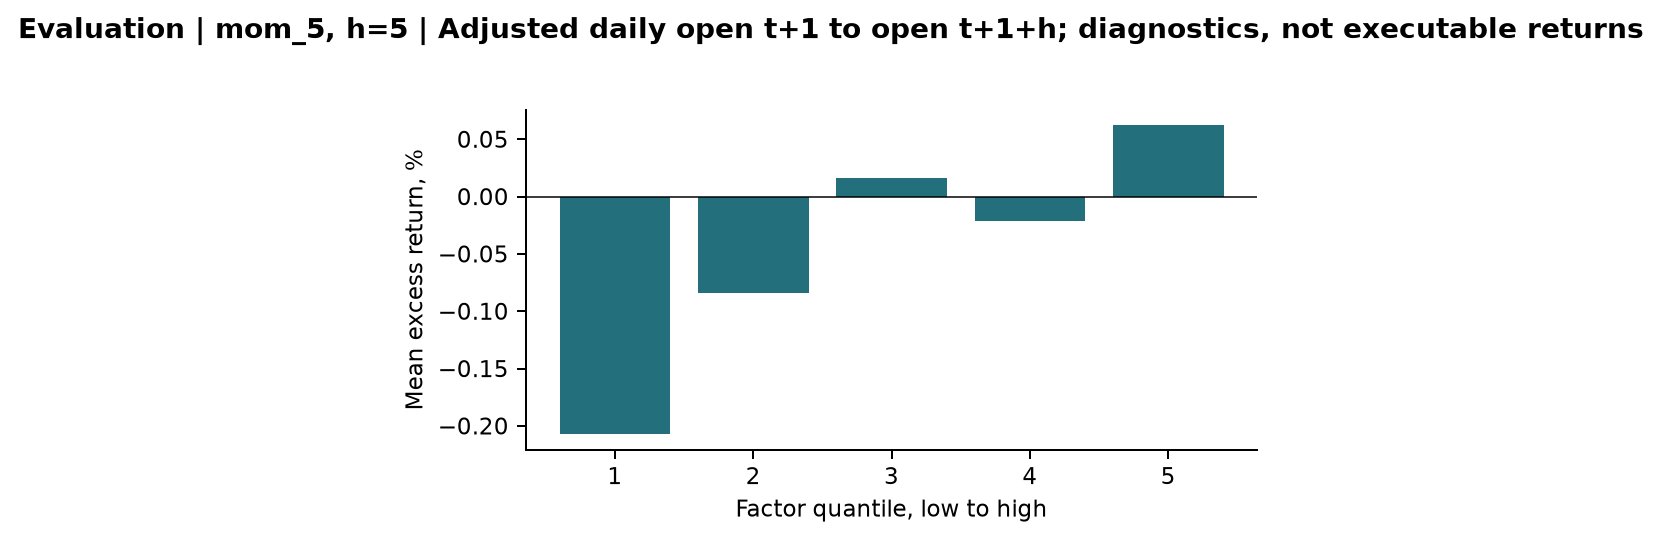

In [5]:
q=pd.read_csv(run/'quantile_summary.csv'); display(q[(q.role=='evaluation')&(q.horizon==5)&(q['quantile']==5)][['factor','dates','mean_return','benchmark_relative']].sort_values('benchmark_relative',ascending=False).head(12)); display(Image(filename=str(run/'figures/evaluation_quantile_mom_5.png')))

## Horizon sensitivity

Every predeclared horizon appears here; no best horizon is selected and called independently validated.

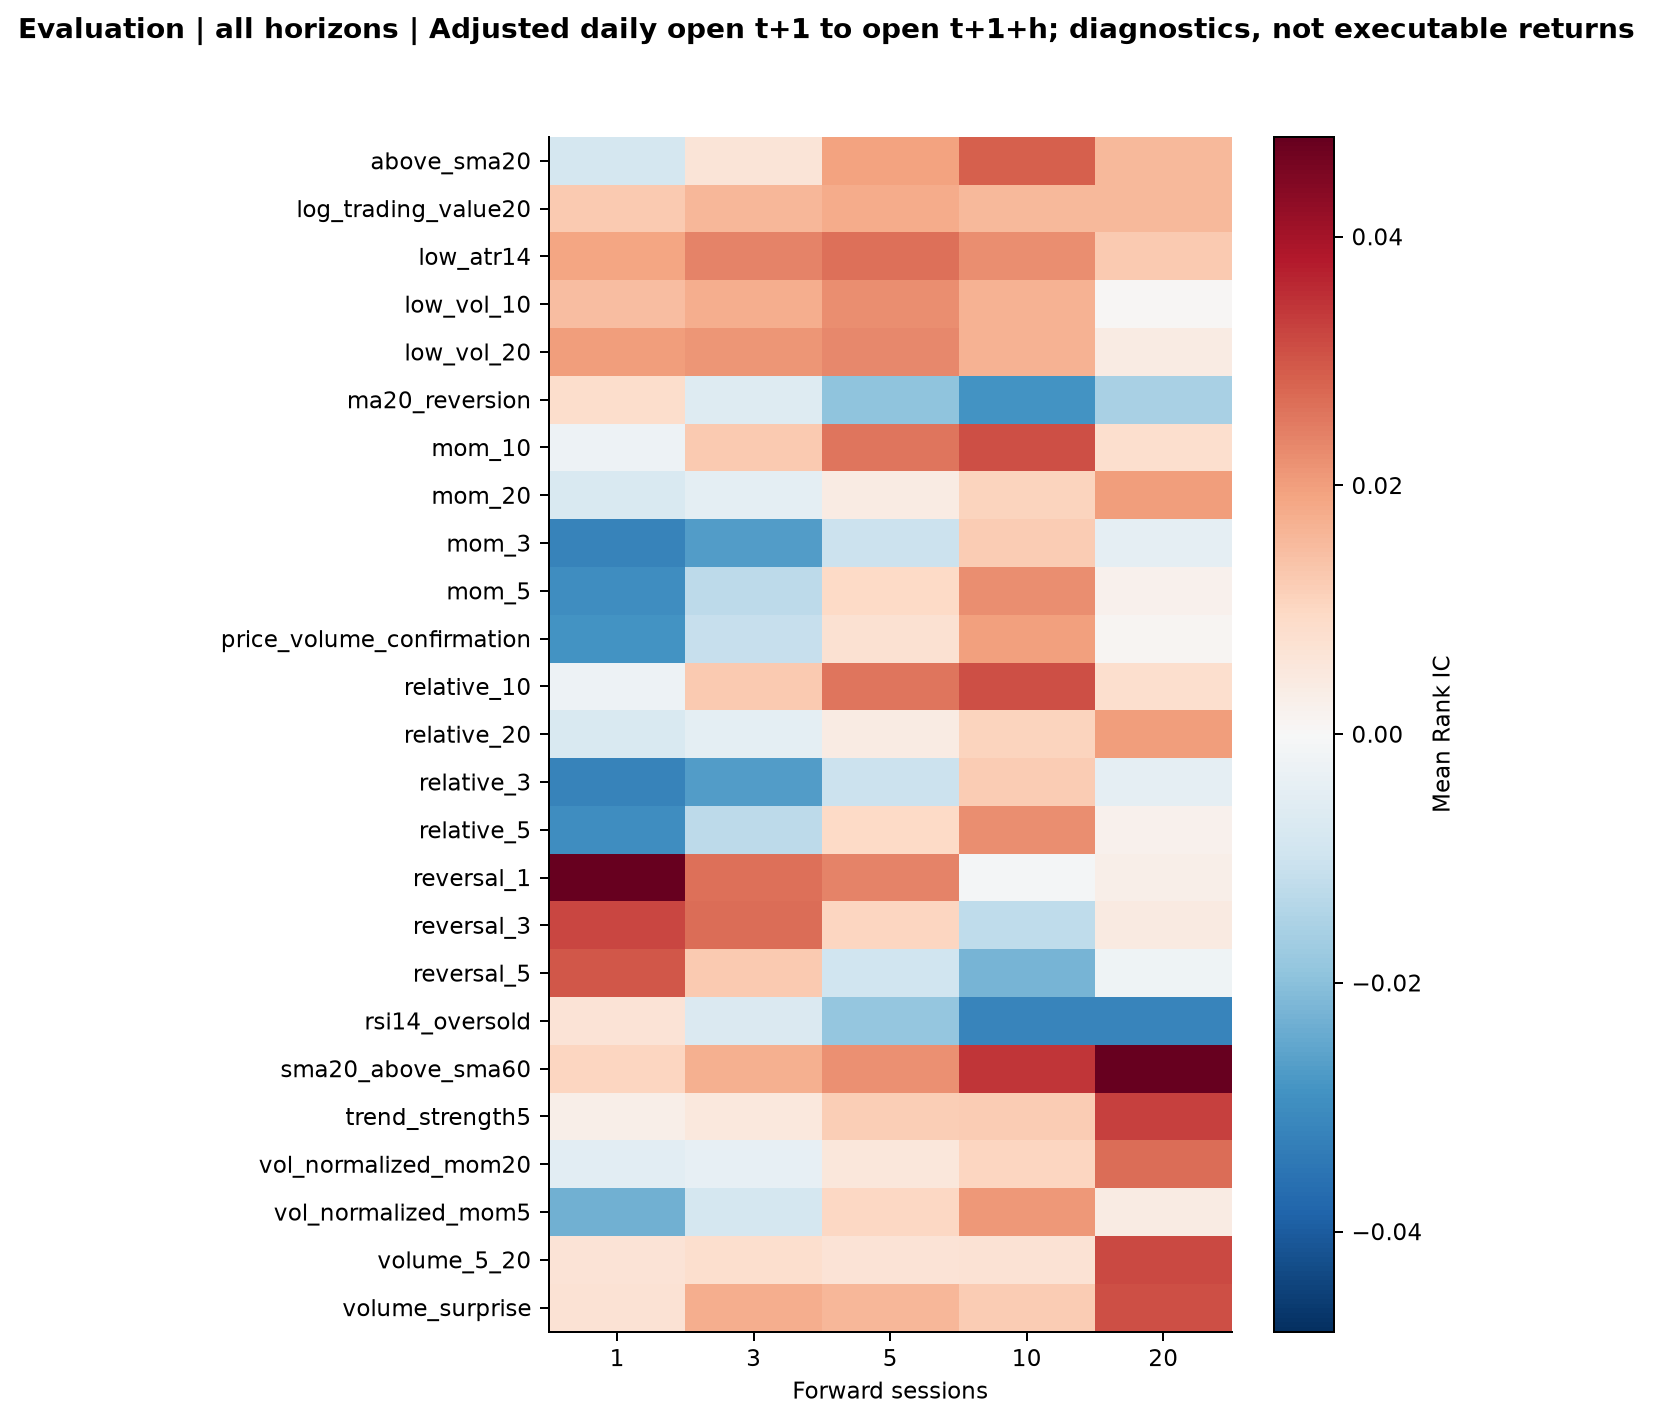

horizon,1,3,5,10,20
factor,,,,,
above_sma20,-0.008,0.006,0.019,0.029,0.016
log_trading_value20,0.013,0.016,0.018,0.016,0.015
low_atr14,0.019,0.024,0.026,0.023,0.013
low_vol_10,0.015,0.018,0.022,0.017,0.001
low_vol_20,0.020,0.021,0.023,0.017,0.004
ma20_reversion,0.008,-0.006,-0.019,-0.029,-0.016
mom_10,-0.002,0.012,0.026,0.031,0.008
mom_20,-0.007,-0.005,0.004,0.011,0.020
mom_3,-0.032,-0.027,-0.010,0.012,-0.004


In [6]:
display(Image(filename=str(run/'figures/evaluation_horizon_heatmap.png'))); display(summary[summary.role=='evaluation'].pivot(index='factor',columns='horizon',values='mean_rank_ic').round(3))

## Stability, regimes, and redundancy

Rolling and cumulative IC are diagnostics, never equity curves. Regimes use information available at signal time. The correlation matrix measures overlapping factor information.

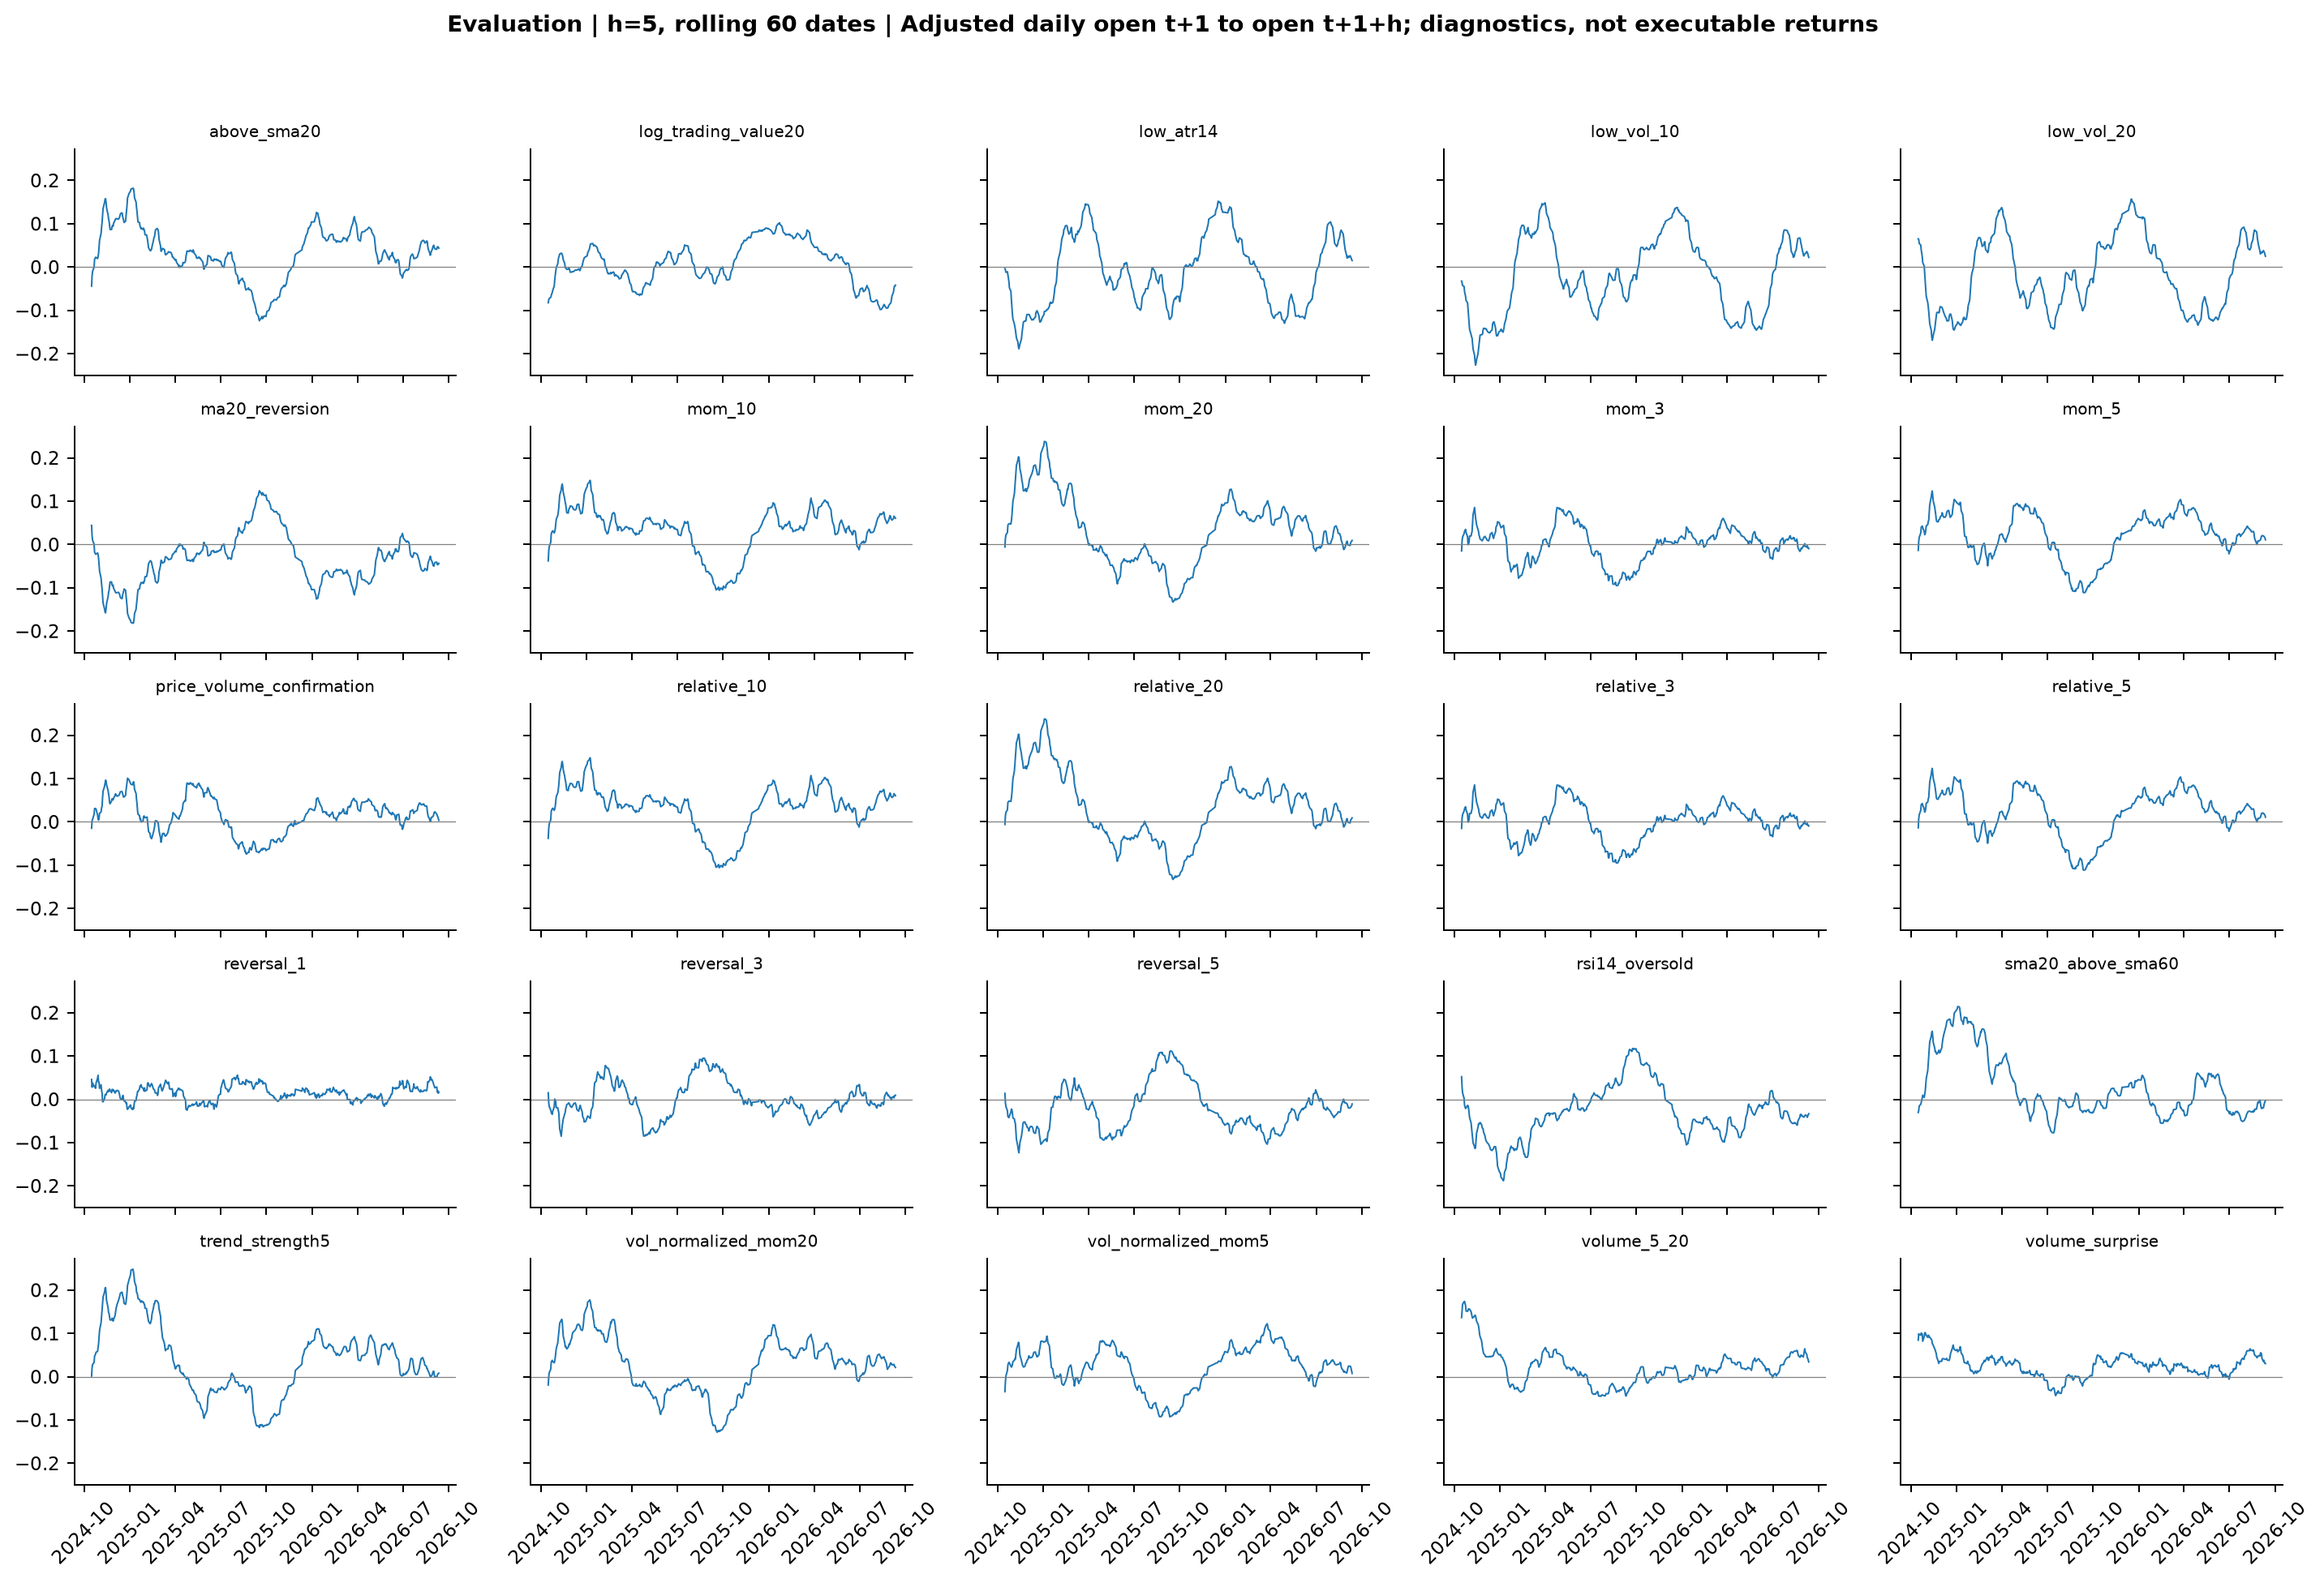

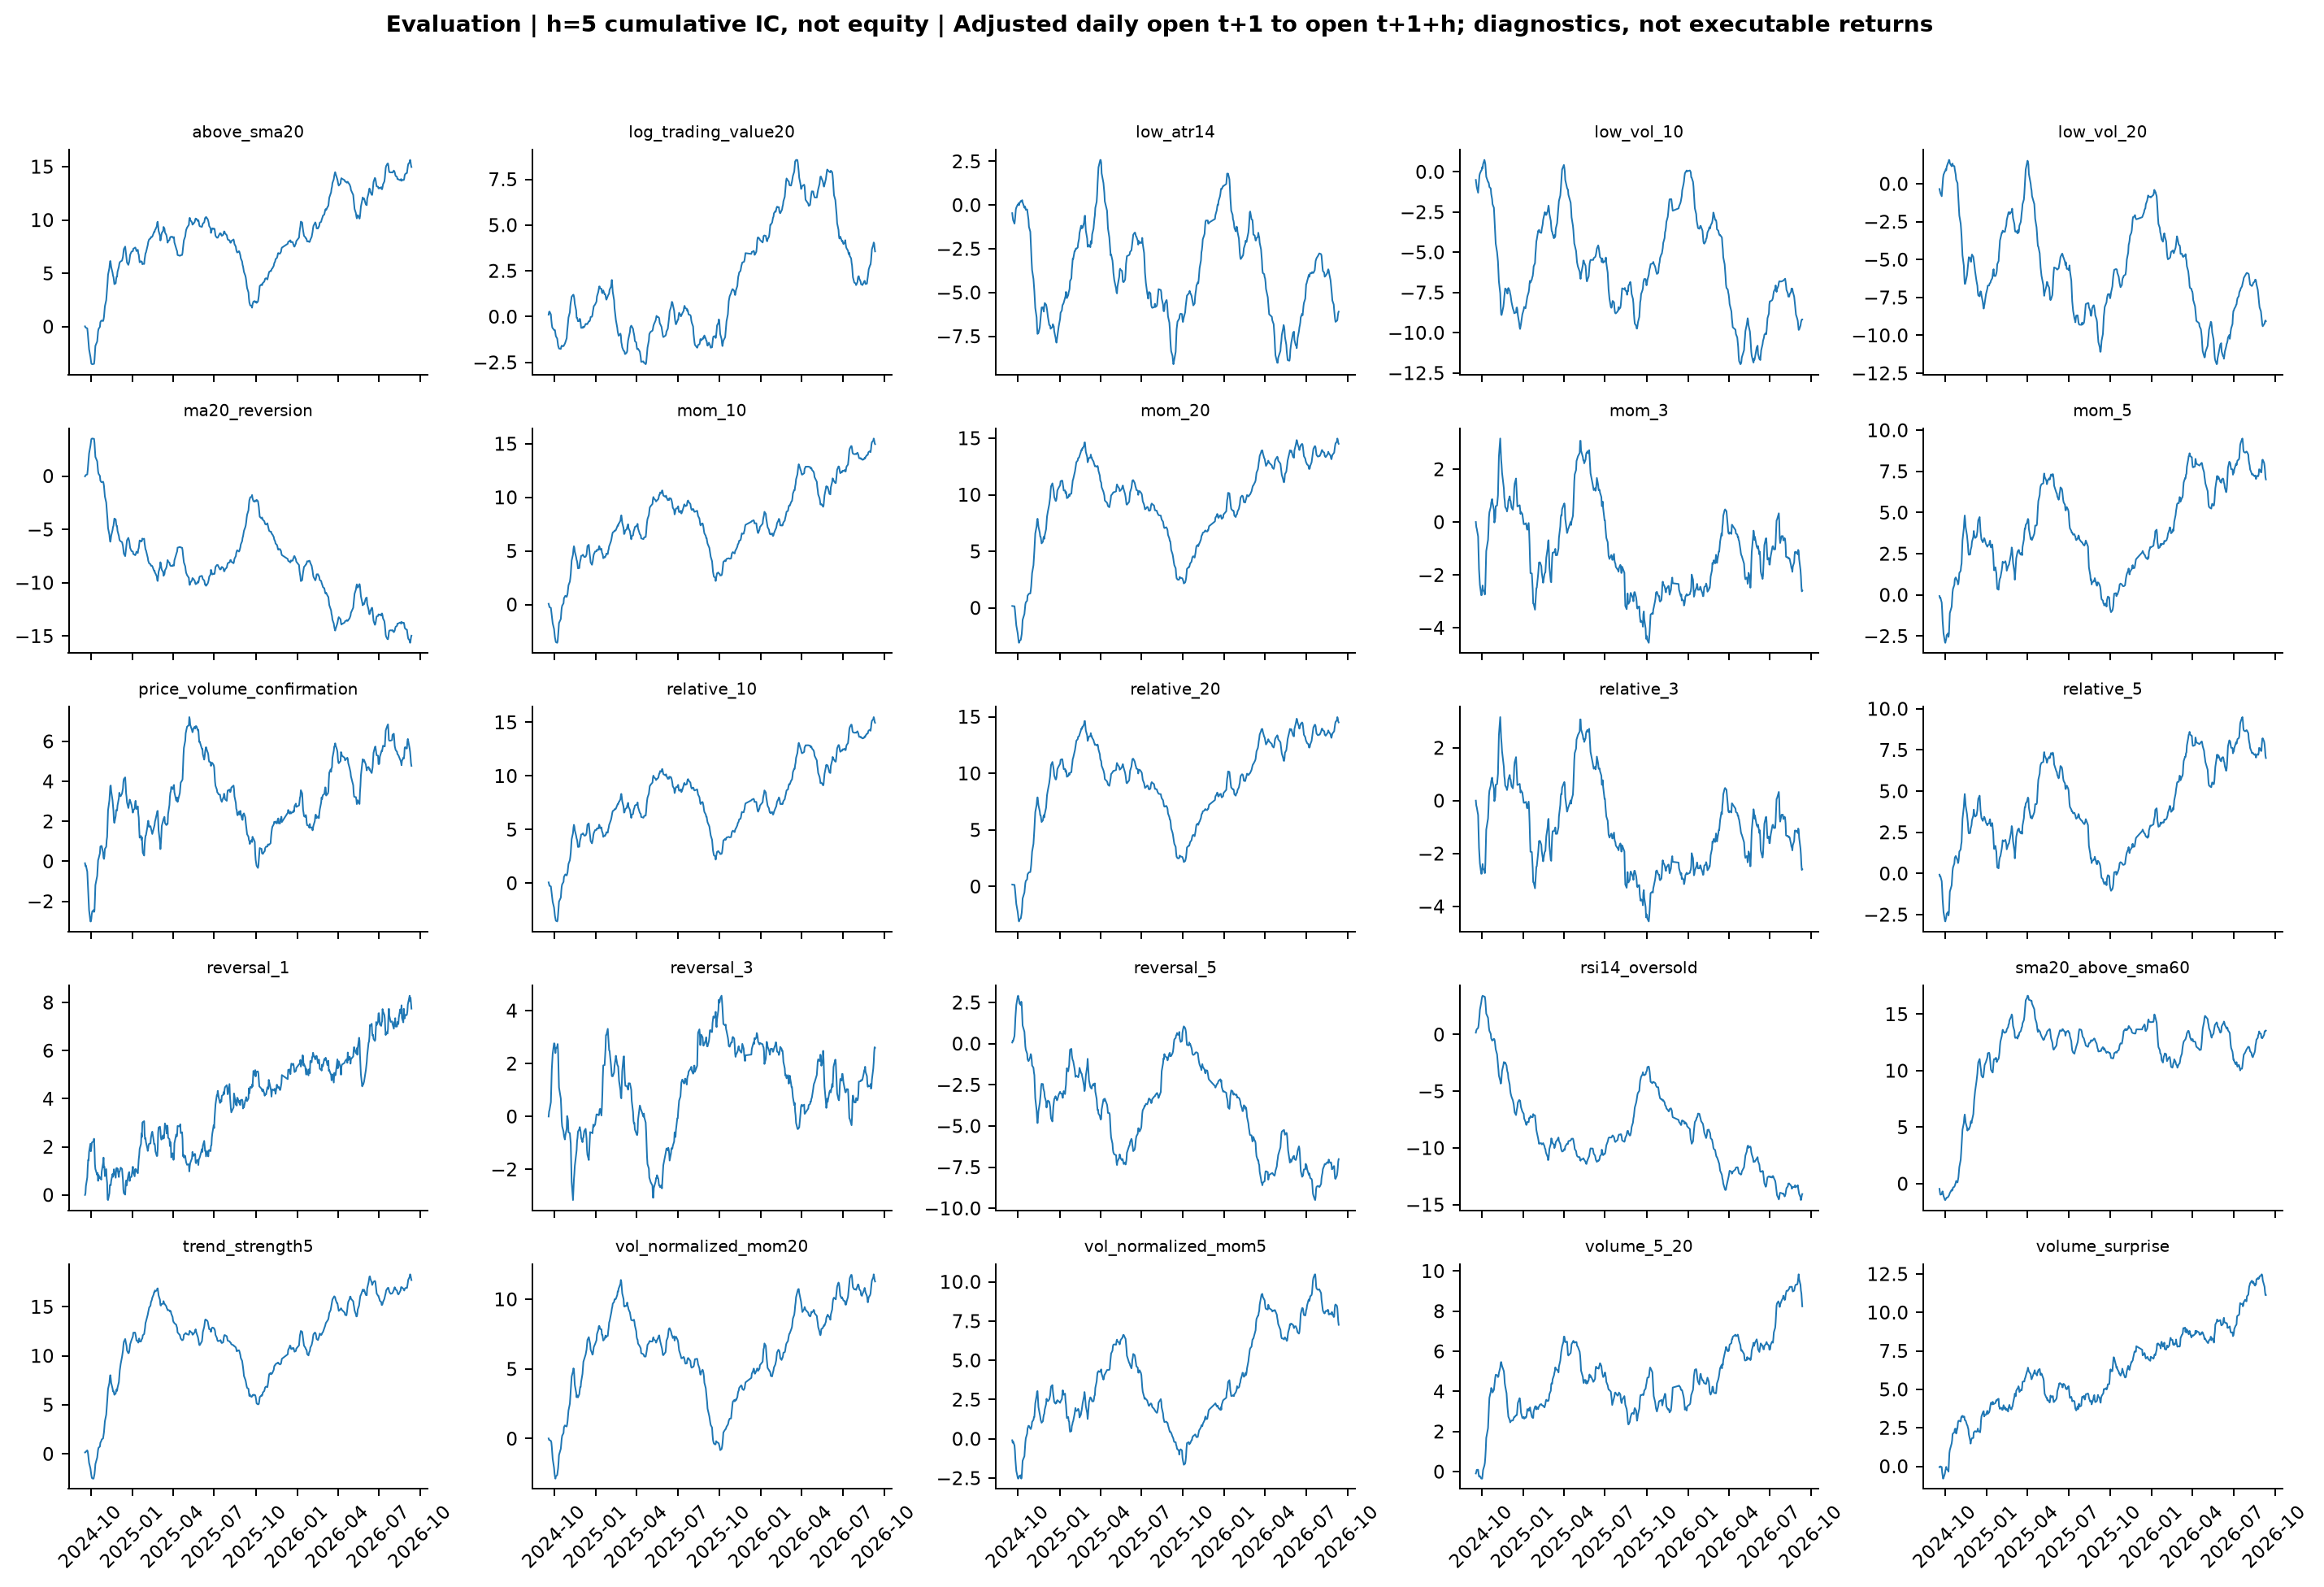

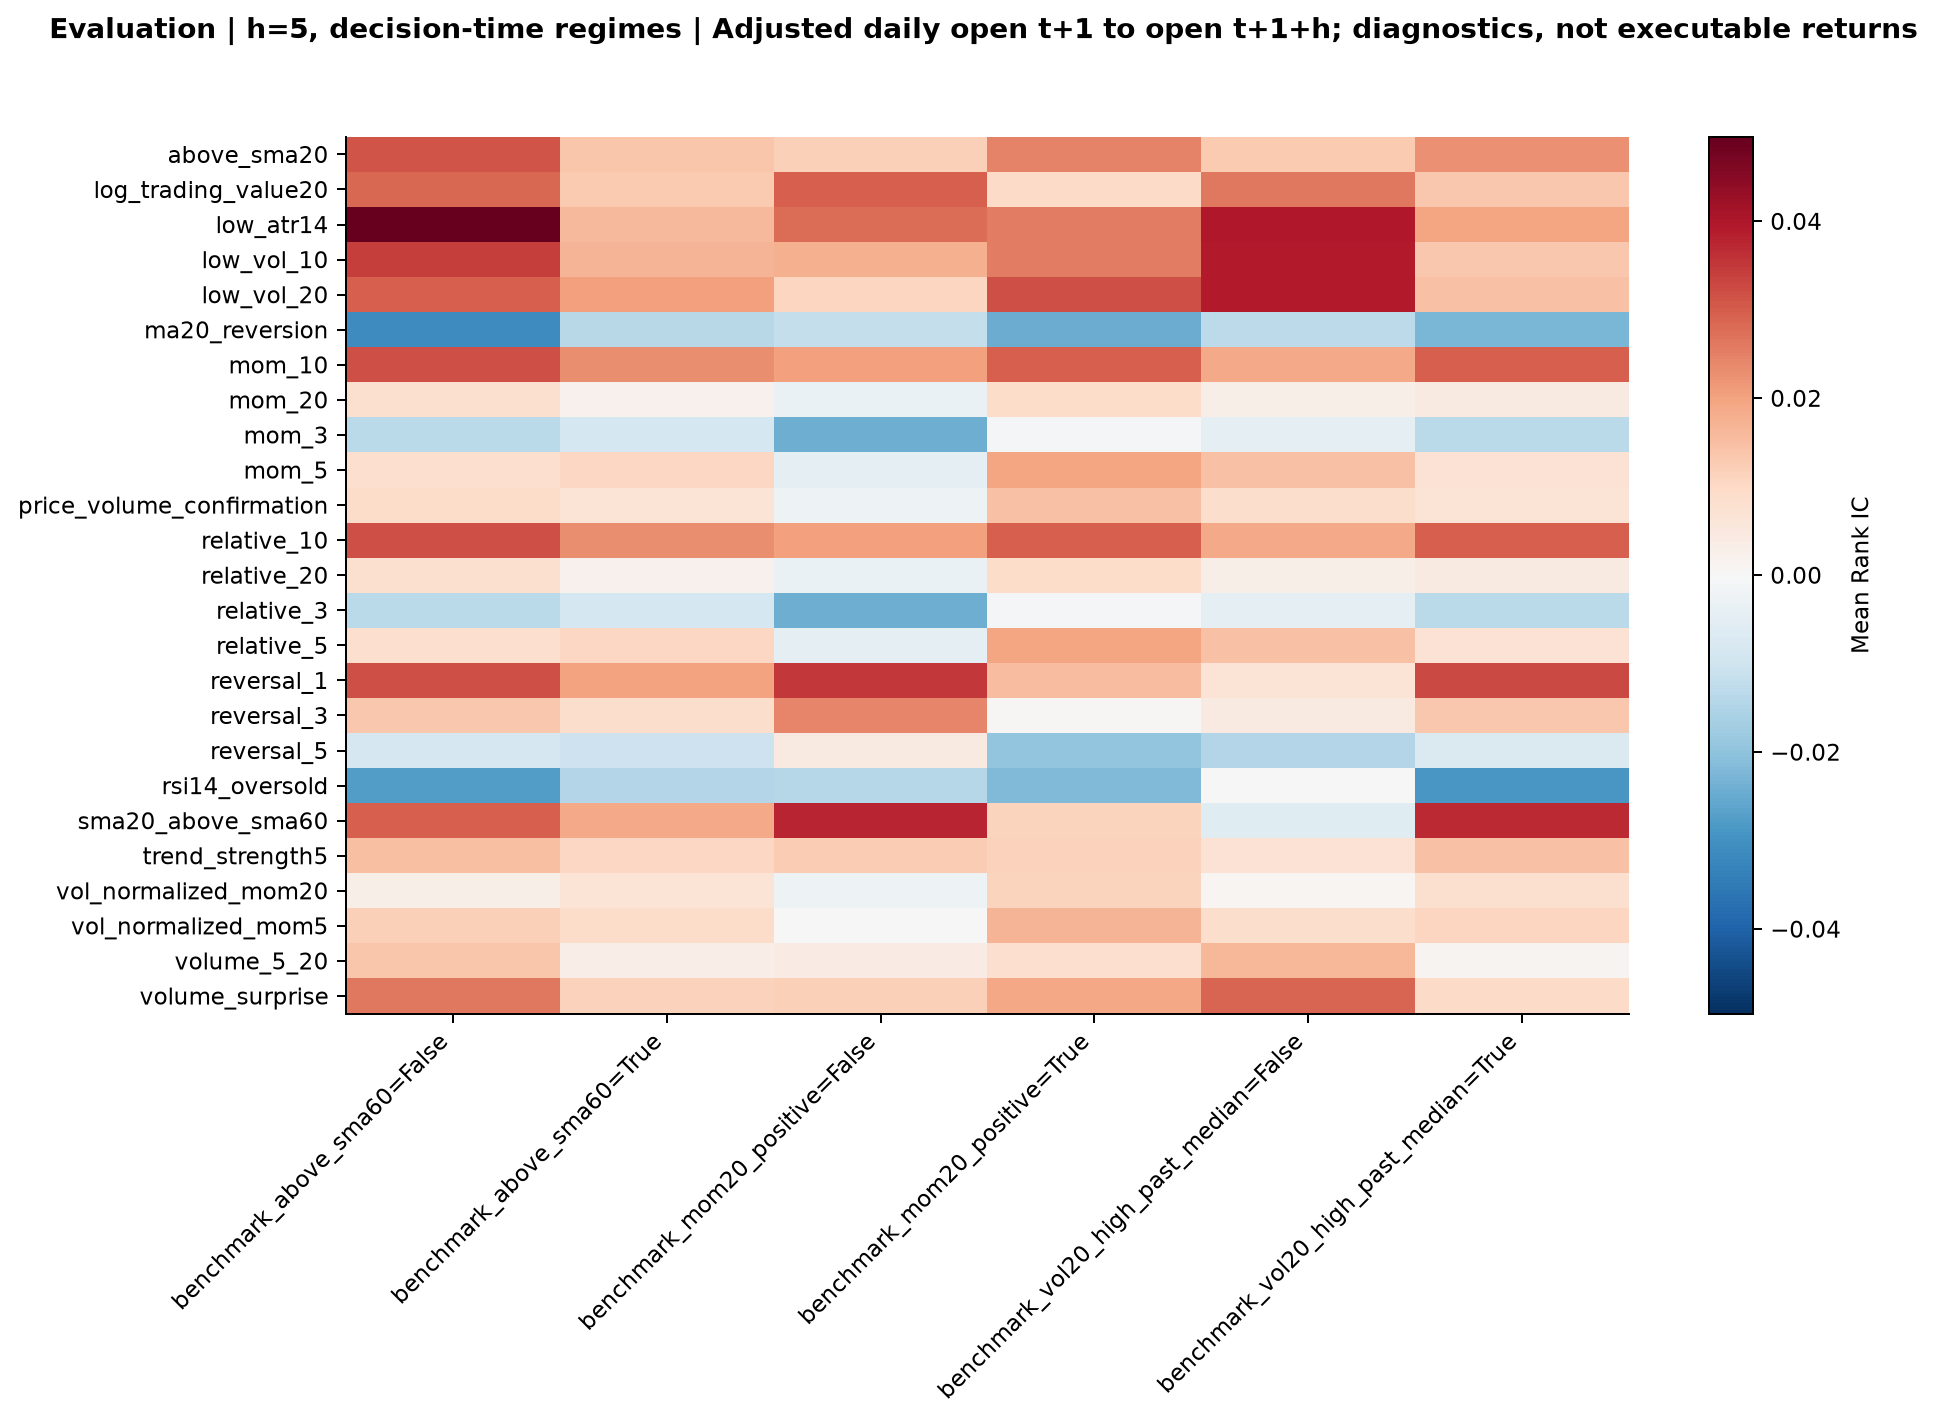

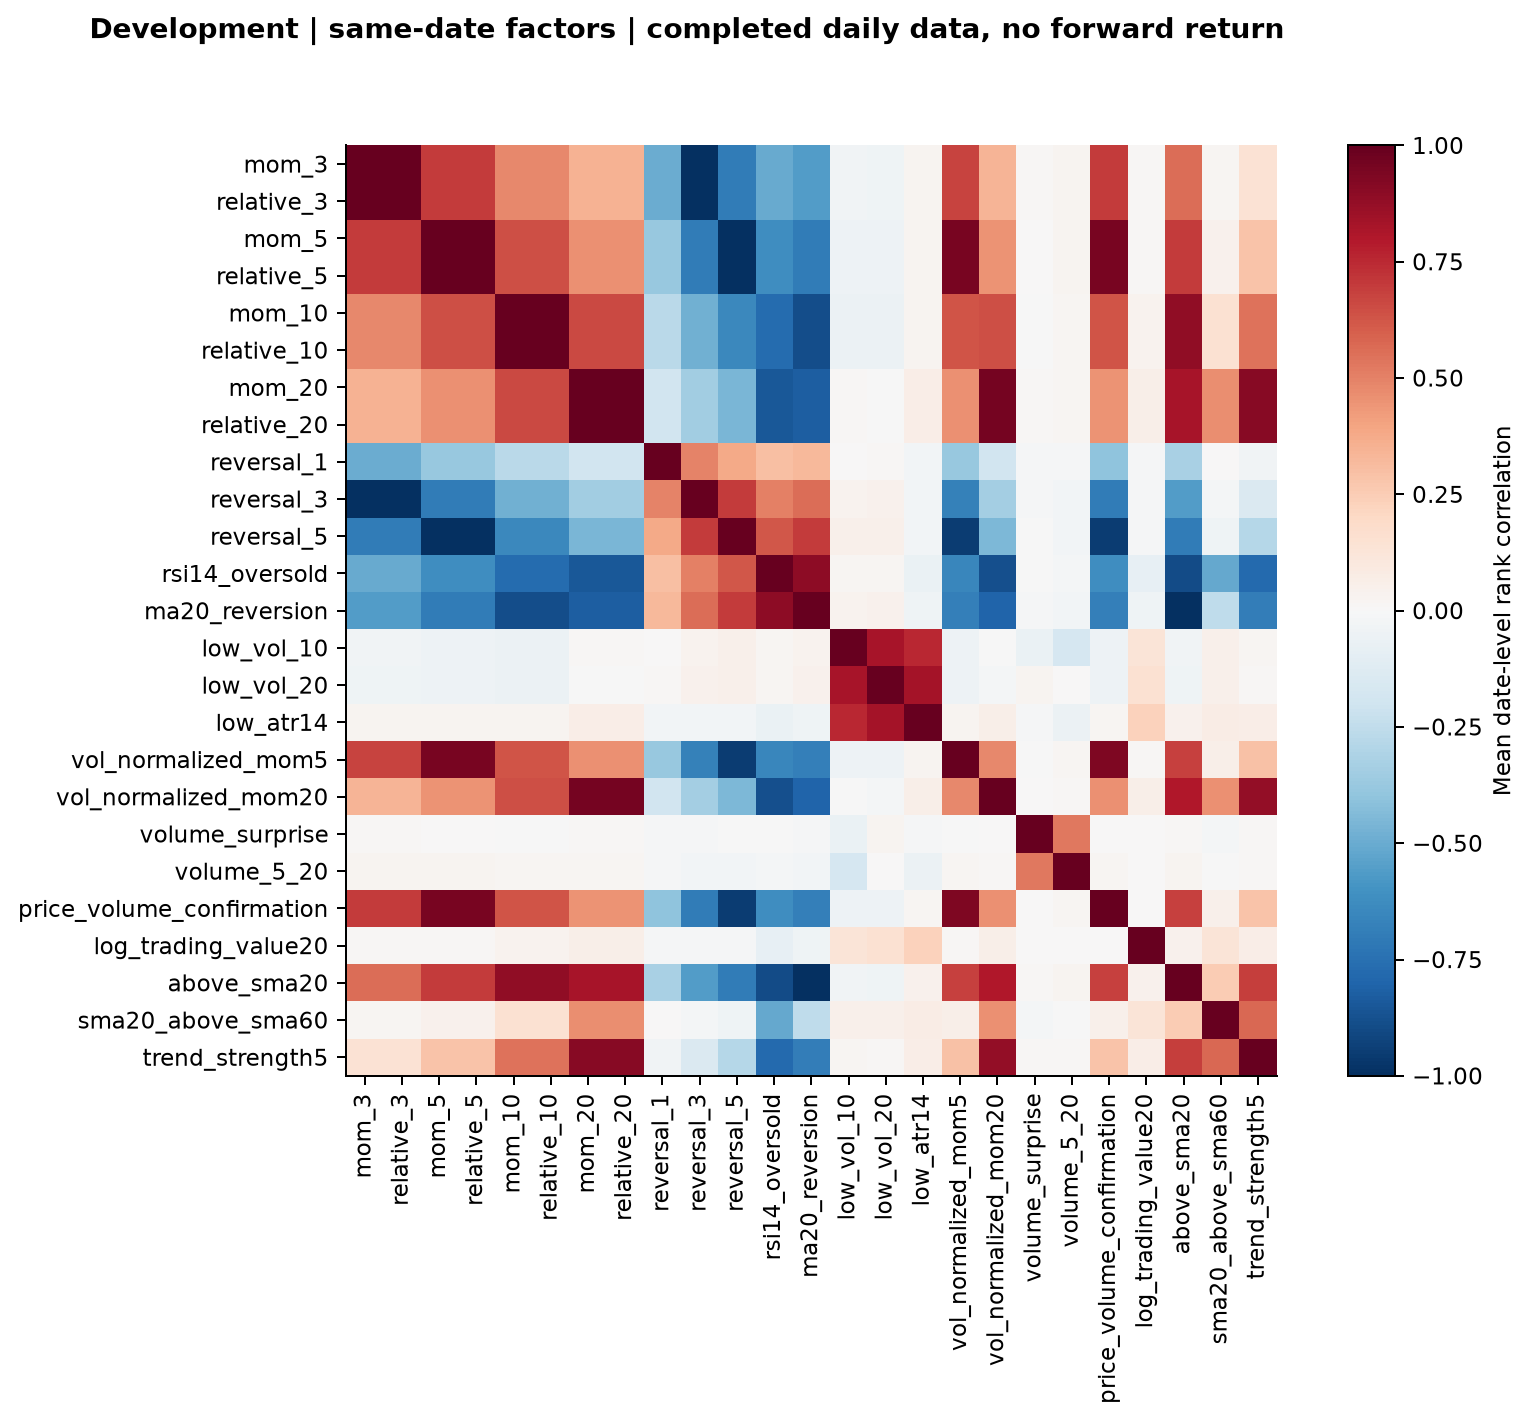

,period_id,mean_rank_ic
1445,window_12,0.059915
1570,window_13,0.105888
1695,window_14,0.078790
1820,window_15,0.013061
1945,window_16,0.045490
2070,window_17,0.051518
2195,window_18,0.063724
2320,window_19,0.100634
2445,window_20,0.070606
2570,window_21,0.011179


In [7]:
display(Image(filename=str(run/'figures/evaluation_rolling_ic.png'))); display(Image(filename=str(run/'figures/evaluation_cumulative_ic.png'))); display(Image(filename=str(run/'figures/evaluation_regime.png'))); display(Image(filename=str(run/'figures/factor_correlation.png'))); segments=pd.read_csv(run/'segment_ic.csv'); display(segments[(segments.factor=='reversal_1')&(segments.horizon==1)&(segments.role=='evaluation')][['period_id','mean_rank_ic']].head(10))

## Turnover and cost diagnostics

Adjusted-open notionals estimate ranking changes and commission floors only. One-tick amounts below use actual raw first-tick reference prices for 16 sessions and are not claimed as fills.

,total_one_way_turnover,commission_vat_thb
factor,,
log_trading_value20,1.728068,29029.807682
sma20_above_sma60,2.279797,38298.302103
low_atr14,2.377341,39936.945789
low_vol_20,2.627613,44141.270787
trend_strength5,3.129057,52565.026443
mom_20,3.644916,61230.940944
relative_20,3.644916,61230.940944
low_vol_10,3.858864,64825.050316
vol_normalized_mom20,3.859898,64842.430002


Raw tick reference rows: 2000


,reference_roundtrip_tick_fraction,reference_total_roundtrip_fraction
count,2000.000000,2000.000000
mean,0.011464,0.014824
std,0.003684,0.003684
min,0.005013,0.008372
25%,0.008130,0.011490
50%,0.011050,0.014410
75%,0.015504,0.018864
max,0.020000,0.023360


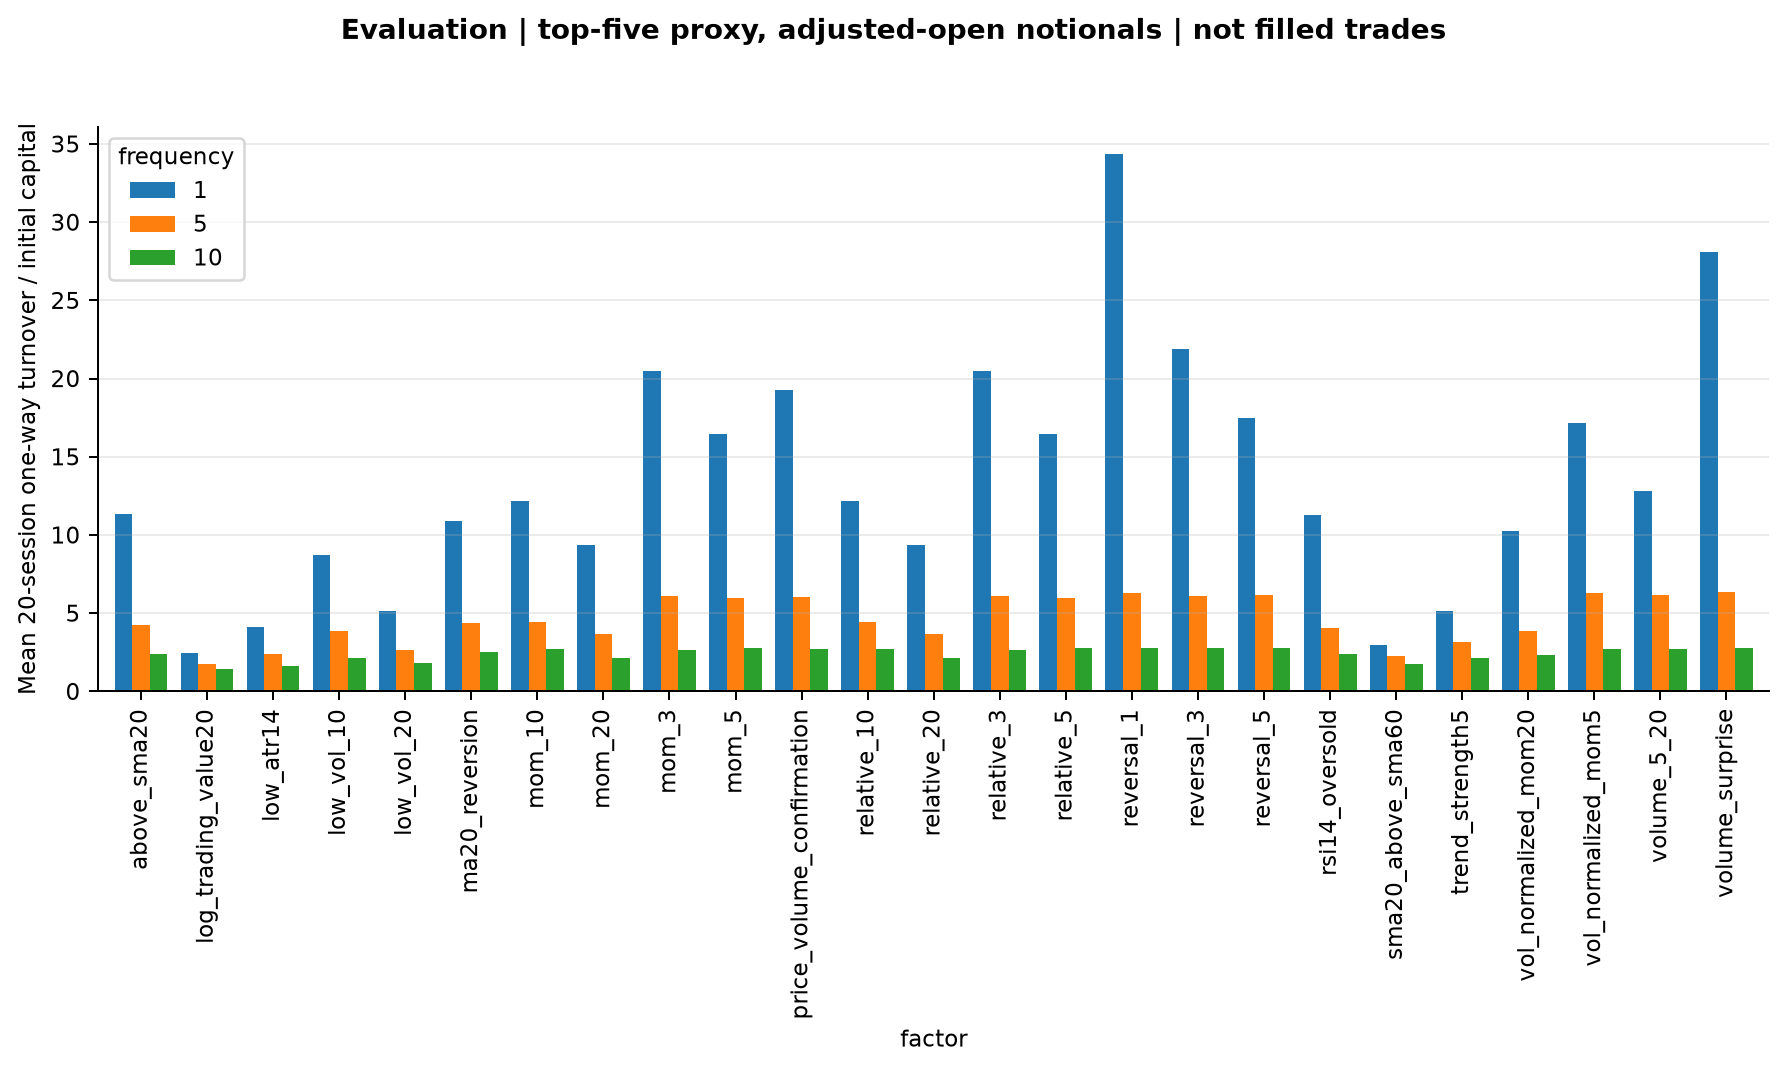

In [8]:
proxy=pd.read_csv(run/'ranking_proxy.csv'); raw=pd.read_csv(run/'raw_tick_cost_reference.csv'); display(proxy[(proxy.role=='evaluation')&(proxy.frequency==5)].groupby('factor')[['total_one_way_turnover','commission_vat_thb']].mean().sort_values('total_one_way_turnover').head(12)); print('Raw tick reference rows:',len(raw)); display(raw[['reference_roundtrip_tick_fraction','reference_total_roundtrip_fraction']].describe()); display(Image(filename=str(run/'figures/evaluation_turnover.png')))

## Phase 1 comparison and statistical interpretation

Phase 1 native momentum and relative equal-weight performance were identical, consistent with their identical rankings. Inverse-volatility sizing changed portfolio outcomes, not the ranking. RSI's native relative outperformance coincided with low exposure and negative expected payoff. Phase 2 date-level IC and quantiles test whether any raw ranking had information before portfolio mechanics. The evaluation dates were already viewed in Phase 1, and revised data plus current-universe membership limit causal claims.

In [9]:
phase1=pd.read_csv('research_set50_baseline/results/native_comparison_16_sessions.csv'); display(phase1[['strategy','net_return','excess_return','average_exposure','expected_payoff','turnover']]); display(ev[['factor','mean_rank_ic','rank_fdr_q']].head(10))

,strategy,net_return,excess_return,average_exposure,expected_payoff,turnover
0,buy_hold,-0.046647,-0.005103,0.971536,NaN,0.986487
1,momentum,-0.065544,-0.024001,0.954491,-24999.710333,3.514683
2,relative_equal,-0.065544,-0.024001,0.954491,-24999.710333,3.514683
3,relative_vol,-0.068110,-0.026567,0.975525,-28801.154828,3.924019
4,rsi_oversold,-0.029185,0.012358,0.341971,-21897.389288,1.806794


,factor,mean_rank_ic,rank_fdr_q
137,low_atr14,0.026386,0.785537
157,mom_10,0.025810,0.785537
182,relative_10,0.025810,0.785537
202,reversal_1,0.023651,0.026545
147,low_vol_20,0.023155,0.785537
142,low_vol_10,0.022274,0.785537
222,sma20_above_sma60,0.022115,0.785537
127,above_sma20,0.019319,0.785537
132,log_trading_value20,0.017896,0.785537
247,volume_surprise,0.016089,0.598537


## Conclusions and Phase 3 decision

One-day reversal has repeatable short-horizon ranking information, but its top-group mean advantage is smaller than the commission-only round trip and its turnover is high. It merits testing only as a tie-breaker for already-planned trades, with incremental turnover measured. Momentum's one-session continuation hypothesis is contradicted; longer-horizon results are unstable and a 20-session target may exit outside the competition window. RSI oversold is unsupported here. No factor is proven profitable or competition eligible. Phase 3 must test completed round-trips, exposure, drawdown, payoff, and actual order fills separately. See `RESEARCH_FINDINGS.md` for the full evidence table.